# 02 – Estimate: linear regression, ridge and lasso (task 20)

All models use the preprocessing pipeline in `pipeline.py` (task 19) and are compared in cross-validation with `cv.py`.

**How we compare models**
- Split and folds come from `01b_split.ipynb` (task 16). The test set is removed right at the start and not used here.
- In every fold, the model is trained on **all buildings** of the other four folds and judged on the **houses** of the
  validation fold (feedback point 1). Results for all buildings are shown next to them.
- Selection measure (README decision 1): share of houses above 450 among the top 20% of the ranking.
- Each model is run **with and without** the expert-rule column (construction period × energy group, target encoding).
- Ridge and lasso: for each one we choose the alpha with the highest mean selection measure over the 5 folds;
  if several alphas have the same mean, the one with the smaller MAE on houses wins.

**What the pipeline does** (fitted on the training part only):

| Branch | Columns | Steps |
|---|---|---|
| numeric | floor_area, floors, dwellings | fill missing with the training median → log → scale |
| categorical | construction_period, building_class, energy_group, heating_system | one 0/1 column per category; rare ones (< 20) merged into "infrequent" |
| municipality | municipality | one 0/1 column per municipality |
| expert rule | construction_period × energy_group | average target of the combination, pulled towards the overall mean (target encoding) → scale |

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from config import SEED, THRESHOLD
from pipeline import split_xy, build_pipeline, ExpertRuleEncoder
from cv import cross_validate, summarize, tune_alpha, best_alpha, plot_validation_curve, plot_lasso_path

processed = Path("../data/processed")
figures = Path("../output/figures")
tables = Path("../output/tables")
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)

## 1. Check the expert rule on a small made-up example

6 made-up buildings, overall mean = 2,400 / 6 = **400**. We use a smoothing of m = 4 so the values are easy to count by hand:
value = (n · mean of combination + 4 · 400) / (n + 4).

In [2]:
toy_X = pd.DataFrame({
    "construction_period": ["A", "A", "A", "A", "B", "C"],
    "energy_group":        ["gas", "gas", "gas", "gas", "oil", "wood"],
})
toy_y = [200, 200, 200, 200, 1000, 600]

rule = ExpertRuleEncoder(smoothing=4).fit(toy_X, toy_y)
print("Overall mean:", rule.global_mean_)        # expect 400
print(rule.rule_values_)
# A|gas:  n=4, mean 200  -> (4*200 + 4*400) / 8 = 300
# B|oil:  n=1, mean 1000 -> (1000 + 4*400) / 5  = 520   (small cell, pulled strongly towards 400)
# C|wood: n=1, mean 600  -> (600 + 4*400) / 5   = 440

new = pd.DataFrame({"construction_period": ["A", "Z"], "energy_group": ["gas", "gas"]})
print(rule.transform(new).ravel())               # expect [300, 400]: unknown combination gets the overall mean

# without smoothing (m = 0) the rule is just the mean of each combination
print(ExpertRuleEncoder(smoothing=0).fit(toy_X, toy_y).rule_values_)  # expect A|gas 200, B|oil 1000, C|wood 600

Overall mean: 400.0
{'A|gas': 300.0, 'B|oil': 520.0, 'C|wood': 440.0}
[300. 400.]
{'A|gas': 200.0, 'B|oil': 1000.0, 'C|wood': 600.0}


## 2. Load the data and lock away the test set

We join the modelling table with the split by EGID and keep only the buildings with a fold number (0–4).

In [3]:
data = pd.read_csv(processed / "building_clean.csv")
split = pd.read_csv(processed / "split.csv")
data = data.merge(split, on="EGID", how="inner", validate="one_to_one")

train = data[data["test"] == False].reset_index(drop=True)   # the test set stays closed until task 26
assert len(data) == len(split), "some buildings have no split entry"
assert train["fold"].notna().all(), "a building without a fold is left"
train["fold"] = train["fold"].astype(int)  # read as 0.0-4.0 because the test rows are empty

X, y, is_house, groups = split_xy(train)
folds = train["fold"].to_numpy()

print("Buildings in cross-validation:", len(train), "| test buildings set aside:", int(data["test"].sum()))
parts_per_group = train.groupby("group_id")["fold"].nunique()
print("Groups in more than one fold:", (parts_per_group > 1).sum())   # expect 0

per_fold = train.groupby("fold").agg(buildings=("EGID", "size"), houses=("house", "sum"))
per_fold["houses above 450 (%)"] = train[train["house"]].groupby("fold")["y"].apply(lambda s: (s > THRESHOLD).mean() * 100).round(1)
per_fold["houses in top 20%"] = (per_fold["houses"] * 0.2).round().astype(int)
per_fold

Buildings in cross-validation: 12710 | test buildings set aside: 2117
Groups in more than one fold: 0


,buildings,houses,houses above 450 (%),houses in top 20%
fold,,,,
0,2542,234,36.3,47
1,2545,235,39.6,47
2,2541,234,37.6,47
3,2541,234,38.9,47
4,2541,234,37.6,47


**Reading the numbers.** If the office picked houses at random, about the share of houses above 450 shown above
(~38%) would be problem houses. A useful model must be clearly above that. With about 47 houses in the top 20%
of a fold, one house more or less changes the measure by about 2 percentage points, so small differences
between models are chance.

## 3. Check the pipeline on one fold (leakage check)

Rule 2: everything that learns from data is fitted on the training part only. We fit the pipeline once on folds 1–4
and apply it to fold 0, then check what it learned. The cross-validation below does exactly this for every fold.

In [4]:
check_train, check_val = folds != 0, folds == 0
pipe = build_pipeline(LinearRegression()).fit(X[check_train], y[check_train])

prep = pipe.named_steps["prep"]
X_val_prep = prep.transform(X[check_val])
names = prep.get_feature_names_out()
print("Columns after preprocessing:", X_val_prep.shape[1])
print("Missing values after preprocessing:", np.isnan(X_val_prep).sum())   # expect 0
print("Expert-rule column present:", "expert_rule" in names)               # expect True

# what the expert rule learned must come from folds 1-4 only, not from fold 0 or the test set
rule = prep.named_transformers_["expert_rule"].named_steps["rule"]
print()
print("Overall mean, learned:", round(rule.global_mean_, 2),
      "| folds 1-4:", round(y[check_train].mean(), 2),
      "| all buildings in cross-validation:", round(y.mean(), 2))
print("Buildings counted in the expert rule:", sum(rule.counts_.values()),
      "| buildings in folds 1-4:", check_train.sum())

assert np.isclose(rule.global_mean_, y[check_train].mean()), "the expert rule did not learn from the training part only"
assert sum(rule.counts_.values()) == check_train.sum(), "the expert rule counted buildings outside the training part"

Columns after preprocessing: 92
Missing values after preprocessing: 0
Expert-rule column present: True

Overall mean, learned: 395.04 | folds 1-4: 395.04 | all buildings in cross-validation: 395.84
Buildings counted in the expert rule: 10168 | buildings in folds 1-4: 10168


## 4. Linear regression

We run it with and without the expert-rule column.

In [5]:
def show(summary, group="houses"):
    # the main numbers of a summary table in percent, for one group
    s = summary[summary["group"] == group].iloc[0]
    return {
        "top 20%: above 450 (%)": round(s["share_above_top20_mean"] * 100, 1),
        "± SE": round(s["share_above_top20_se"] * 100, 1),
        "top 10%: above 450 (%)": round(s["share_above_top10_mean"] * 100, 1),
        "top 20%: captured (%)": round(s["captured_top20_mean"] * 100, 1),
        "MAE": round(s["mae_mean"], 1),
    }

lr = {}
for expert_rule in [True, False]:
    per_fold_lr, oof = cross_validate(lambda: build_pipeline(LinearRegression(), expert_rule=expert_rule),
                                      X, y, is_house, folds)
    lr[expert_rule] = {"summary": summarize(per_fold_lr), "per_fold": per_fold_lr, "oof": oof}

pd.DataFrame({f"LR, expert rule {'on' if er else 'off'}": show(lr[er]["summary"]) for er in [True, False]}).T

,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE
"LR, expert rule on",54.0,3.1,49.2,28.6,104.8
"LR, expert rule off",53.6,2.4,48.3,28.3,104.5


In [6]:
# the same per fold, houses only: how much does the measure move between folds?
pd.DataFrame({
    f"expert rule {'on' if er else 'off'}": lr[er]["per_fold"].query("group == 'houses'").set_index("fold")["share_above_top20"].mul(100).round(1)
    for er in [True, False]
})

,expert rule on,expert rule off
fold,,
0,46.8,48.9
1,46.8,46.8
2,61.7,57.4
3,57.4,57.4
4,57.4,57.4


## 5. Ridge and lasso: try many values of alpha

alpha sets how strongly large coefficients are penalised. We try values on a log scale: ridge from 0.01 to 100,000,
lasso from 0.001 to 100 (above that lasso sets almost all coefficients to zero).

In [7]:
RIDGE_ALPHAS = np.logspace(-2, 5, 29)
LASSO_ALPHAS = np.logspace(-3, 2, 26)

warnings.filterwarnings("ignore", message="Objective did not converge")  # lasso at the smallest alphas; results are stable

results = {}
for name, model_class, alphas, kwargs in [("Ridge", Ridge, RIDGE_ALPHAS, None),
                                          ("Lasso", Lasso, LASSO_ALPHAS, {"max_iter": 10000})]:
    for expert_rule in [True, False]:
        table = tune_alpha(model_class, alphas, X, y, is_house, folds, model_kwargs=kwargs, expert_rule=expert_rule)
        table.insert(0, "model", name)
        table.insert(1, "expert_rule", expert_rule)
        results[(name, expert_rule)] = table
        print(name, "| expert rule", "on " if expert_rule else "off", "| best alpha:", round(best_alpha(table), 4))

Ridge | expert rule on  | best alpha: 562.3413
Ridge | expert rule off | best alpha: 0.01
Lasso | expert rule on  | best alpha: 0.001
Lasso | expert rule off | best alpha: 0.631


## 6. Which alpha? Validation curves

Top: share of houses above 450 in the top 20% (mean over the 5 folds; band = ± one standard error).
Bottom: MAE on houses. The grey lines are references: random choice, the two baselines of task 18
(training mean and expert rule, read from `output/tables/task18_baselines.csv`) and linear regression without penalty.

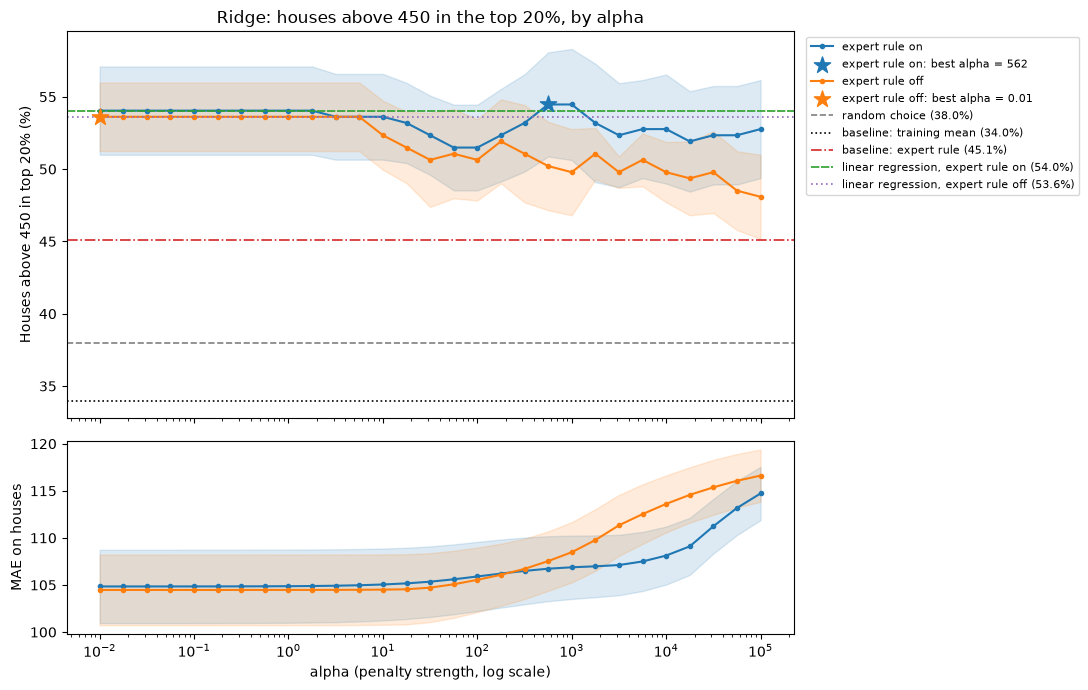

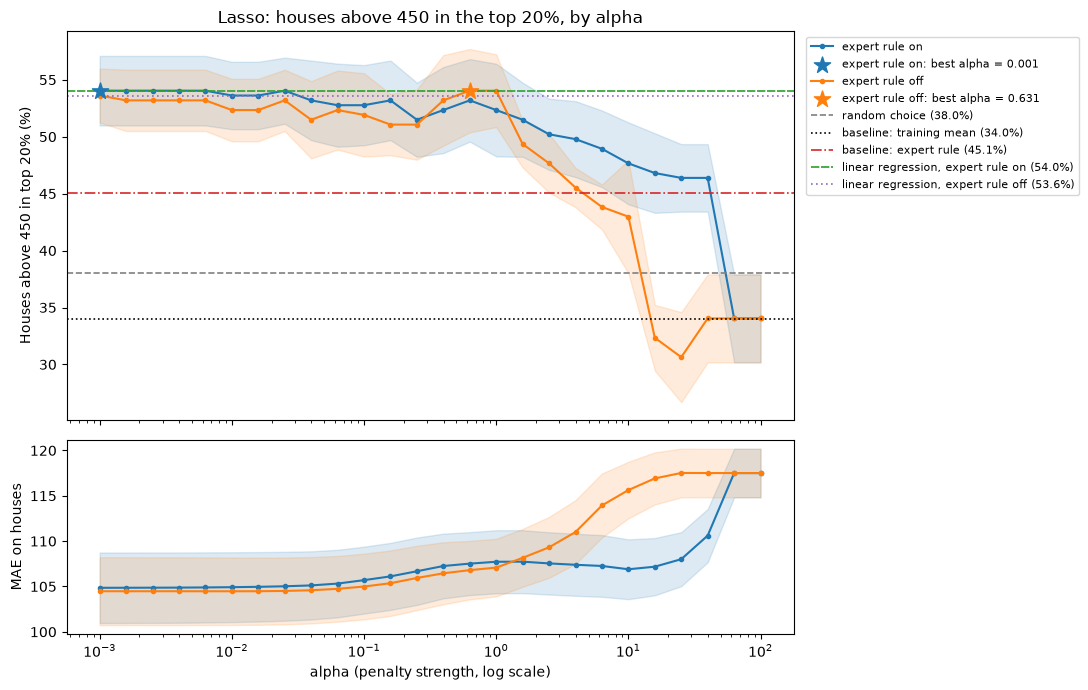

In [8]:
random_share = (y[is_house] > THRESHOLD).mean()
reference = {f"random choice ({random_share * 100:.1f}%)": random_share}

# Baselines (task 18): same folds and measures, results saved by Person 3
baseline_file = Path("../output/tables/task18_baselines.csv")
if baseline_file.exists():
    baselines = pd.read_csv(baseline_file).query("group == 'houses'")
    for _, row in baselines.iterrows():
        share = row["top 20%: above 450 (%)"] / 100
        reference[f"baseline: {row['model'].lower()} ({share * 100:.1f}%)"] = share
else:
    print("task18_baselines.csv not found - plotted without the baselines")

for rule in [True, False]:
    share = lr[rule]["summary"].query("group == 'houses'")["share_above_top20_mean"].iloc[0]
    reference[f"linear regression, expert rule {'on' if rule else 'off'} ({share * 100:.1f}%)"] = share

for name in ["Ridge", "Lasso"]:
    plot_validation_curve(
        {"expert rule on": results[(name, True)], "expert rule off": results[(name, False)]},
        title=f"{name}: houses above 450 in the top 20%, by alpha",
        reference=reference,
        path=figures / f"task20_{name.lower()}_validation_curve.png",
    )
    plt.show()

## 7. Lasso: which features survive?

Lasso fitted on all buildings in cross-validation (no test set) for every alpha. This only describes the model;
alpha is chosen in section 5. The expert-rule column is drawn thicker.

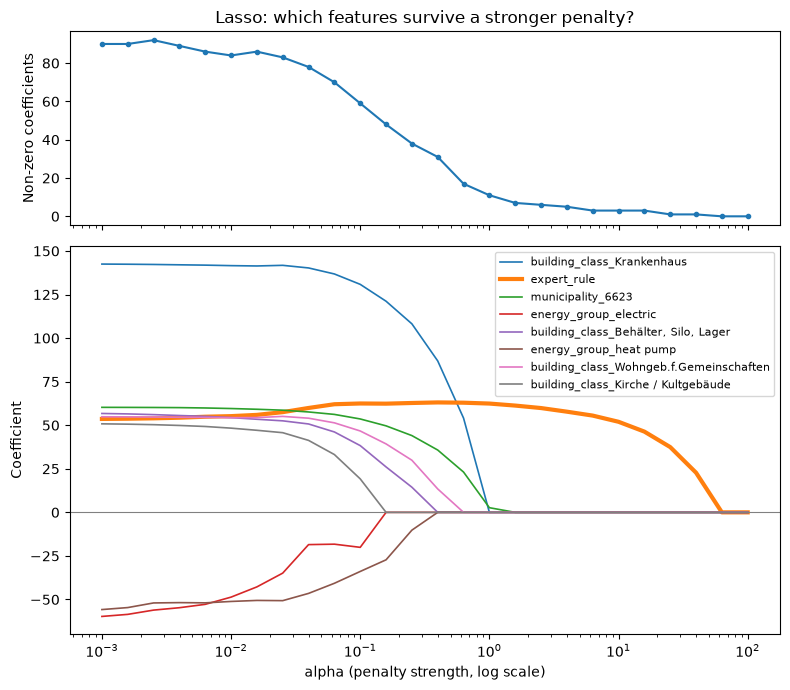

In [9]:
fig, lasso_coefs = plot_lasso_path(X, y, LASSO_ALPHAS, n_show=8, expert_rule=True,
                                   path=figures / "task20_lasso_path.png")
plt.show()

## 8. Overview: all six variants with their chosen setting

Houses first, all buildings next to them.

In [10]:
variants = [("Linear regression", None, True), ("Linear regression", None, False)]
for name in ["Ridge", "Lasso"]:
    for expert_rule in [True, False]:
        variants.append((name, best_alpha(results[(name, expert_rule)]), expert_rule))

rows, oof_scores = [], {}
for name, alpha, expert_rule in variants:
    if name == "Linear regression":
        summary, oof = lr[expert_rule]["summary"], lr[expert_rule]["oof"]
    else:
        model_class = Ridge if name == "Ridge" else Lasso
        kwargs = {"max_iter": 10000} if name == "Lasso" else {}
        per_fold_v, oof = cross_validate(lambda: build_pipeline(model_class(alpha=alpha, **kwargs), expert_rule=expert_rule),
                                         X, y, is_house, folds)
        summary = summarize(per_fold_v)
    label = f"{name}, expert rule {'on' if expert_rule else 'off'}"
    oof_scores[label] = oof
    for group in ["houses", "all buildings"]:
        rows.append({"model": name, "alpha": alpha, "expert_rule": expert_rule, "group": group, **show(summary, group)})

chosen = pd.DataFrame(rows)

# one row per variant: houses in full, the main numbers for all buildings next to them
houses = chosen[chosen["group"] == "houses"].drop(columns="group").reset_index(drop=True)
all_buildings = (chosen[chosen["group"] == "all buildings"][["top 20%: above 450 (%)", "MAE"]]
                 .reset_index(drop=True).add_prefix("all buildings: "))
overview = pd.concat([houses, all_buildings], axis=1)
overview["alpha"] = overview["alpha"].map(lambda a: "–" if pd.isna(a) else f"{a:.3g}")
overview

,model,alpha,expert_rule,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE,all buildings: top 20%: above 450 (%),all buildings: MAE
0,Linear regression,–,True,54.0,3.1,49.2,28.6,104.8,57.0,75.4
1,Linear regression,–,False,53.6,2.4,48.3,28.3,104.5,56.4,75.5
2,Ridge,562,True,54.5,3.6,43.1,28.7,106.7,56.1,76.5
3,Ridge,0.01,False,53.6,2.4,48.3,28.3,104.5,56.4,75.5
4,Lasso,0.001,True,54.0,3.1,49.2,28.6,104.9,57.1,75.4
5,Lasso,0.631,False,54.0,3.7,44.0,28.5,106.8,55.1,76.9


## 9. Save the results

- `output/tables/task20_cv_results.csv`: every alpha of ridge and lasso, with and without the expert rule
- `output/tables/task20_chosen.csv`: the six variants above
- `output/tables/task20_oof_predictions.csv`: out-of-fold predictions of the six variants (every building predicted by
  the model that did not see it), for the error plot and the error analysis (task 24)

In [11]:
pd.concat(results.values(), ignore_index=True).to_csv(tables / "task20_cv_results.csv", index=False)
chosen.to_csv(tables / "task20_chosen.csv", index=False)

oof_table = train[["EGID", "fold", "house", "y"]].copy()
for label, score in oof_scores.items():
    oof_table[label] = score
oof_table.to_csv(tables / "task20_oof_predictions.csv", index=False)
print("Saved:", len(results), "tuning tables,", len(chosen), "rows of chosen variants,", len(oof_table), "out-of-fold predictions")

Saved: 4 tuning tables, 12 rows of chosen variants, 12710 out-of-fold predictions
